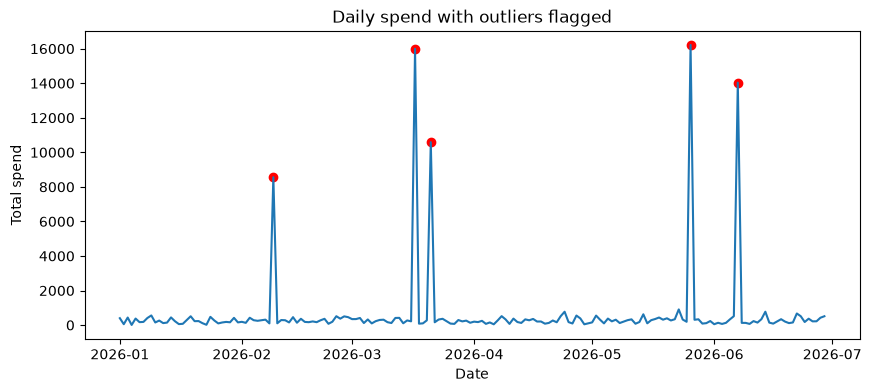

In [4]:
import matplotlib.pyplot as plt

from ledgerlens.cleaning import load_transactions
from ledgerlens.detection import find_outliers

# 1. Load and clean (path starts with ../ because the notebook is inside demo_notebooks/)
clean, rejected, dups = load_transactions("../data/transactions_raw.csv")

# 2. Find outliers (this defines the missing variable)
outliers = find_outliers(clean)

# 3. Total spend per day
daily = {}                                          # {date: total spend}
for t in clean:
    daily[t.date] = daily.get(t.date, 0) + t.amount

days = sorted(daily)      
plt.figure(figsize=(10,4))# sorted dates
plt.plot(days, [daily[d] for d in days])

# highlight outliers as red dots
plt.scatter([t.date for t in outliers], [daily[t.date] for t in outliers], color="red")
plt.title("Daily spend with outliers flagged")
plt.xlabel("Date")
plt.ylabel("Total spend")
plt.show()